In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

sns.set_theme(style="whitegrid")

Pandas version: 2.3.3
NumPy version: 2.2.6


In [2]:
# Load the Titanic dataset
df = sns.load_dataset("titanic")

# Display the first 5 rows
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
# Basic dataset profile

print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (891, 15)

Data types:
survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

Missing values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Duplicate rows: 107


In [4]:
# Summary statistics for numeric columns
summary_stats = df.describe().T

summary_stats

,count,mean,std,min,25%,50%,75%,max
survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
sibsp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


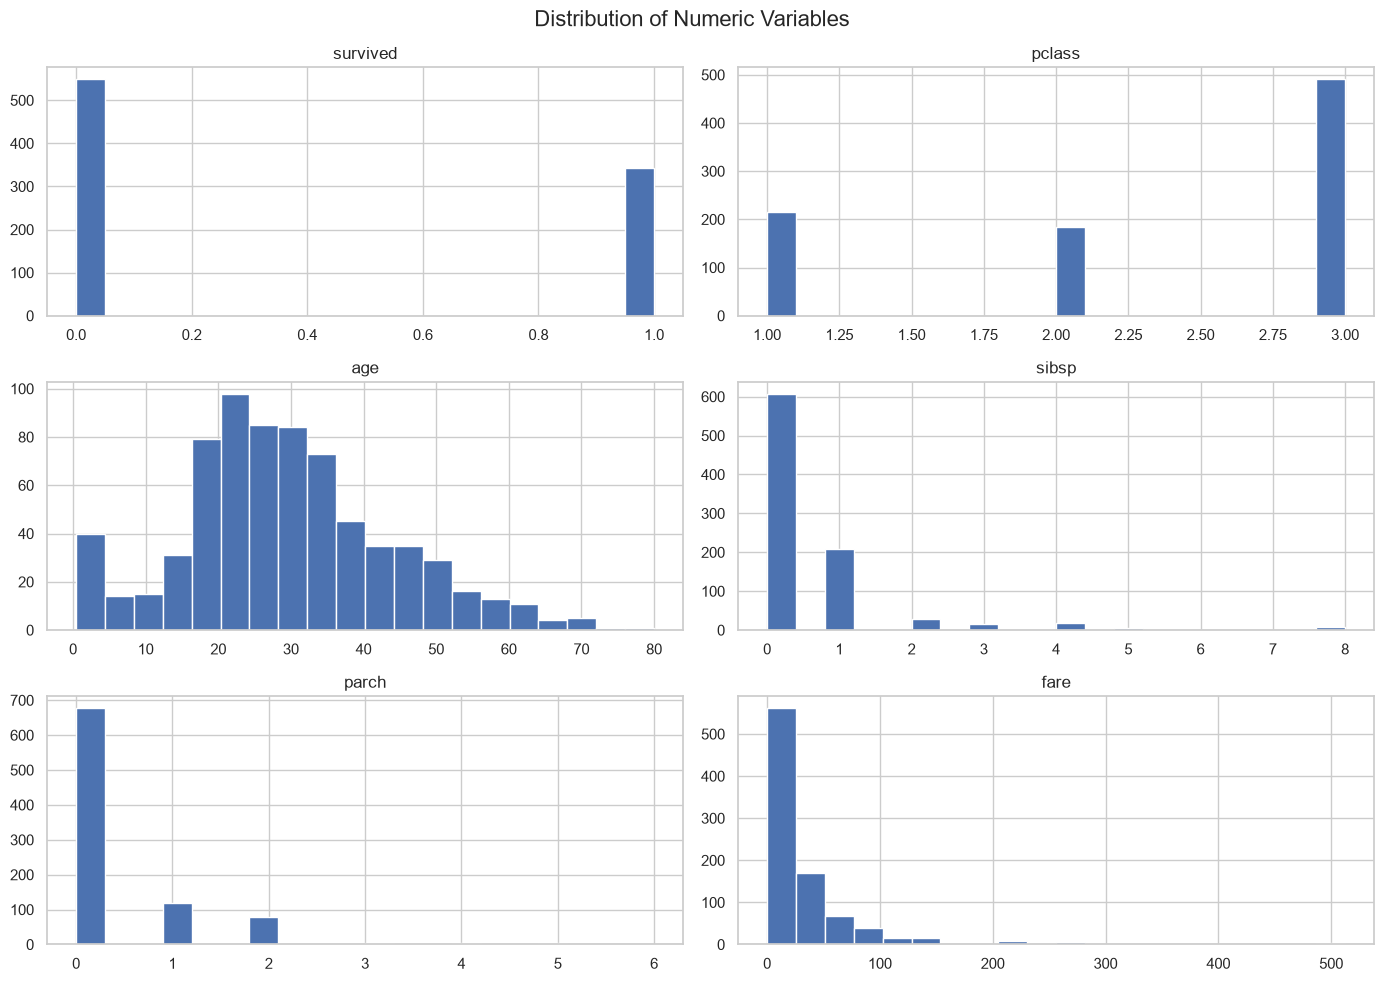

In [5]:
# Visualise distributions for all numeric columns

numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns].hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle("Distribution of Numeric Variables", fontsize=16)
plt.tight_layout()
plt.show()

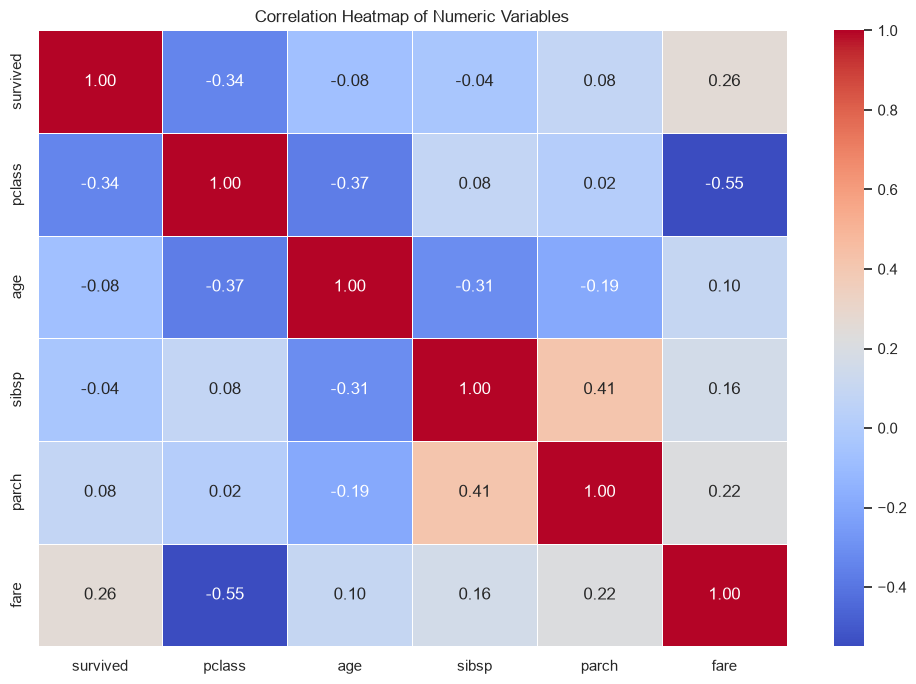

In [6]:
# Correlation heatmap

correlation_matrix = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

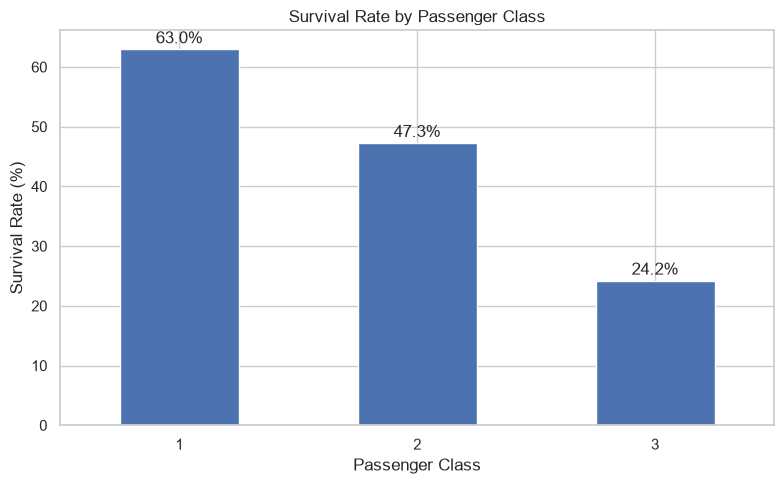

In [7]:
# Insight 1: Survival rate by passenger class

survival_by_class = df.groupby("pclass")["survived"].mean() * 100

plt.figure(figsize=(8, 5))
ax = survival_by_class.plot(kind="bar")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)

for i, value in enumerate(survival_by_class):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

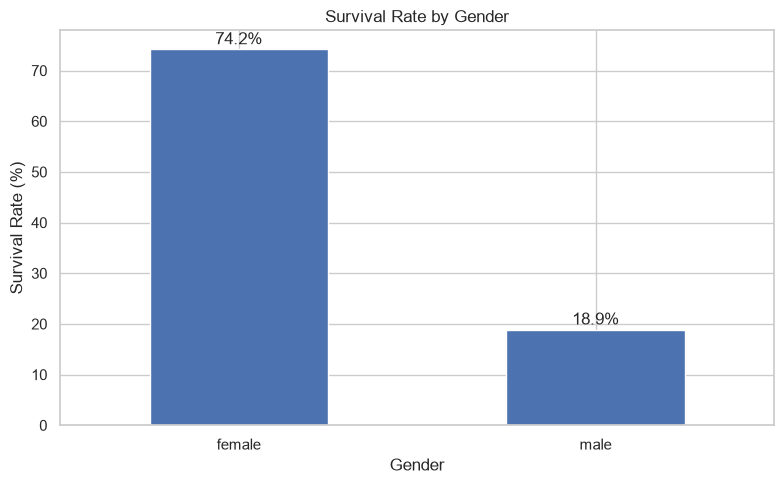

In [8]:
# Insight 2: Survival rate by gender

survival_by_sex = df.groupby("sex")["survived"].mean() * 100

plt.figure(figsize=(8, 5))
ax = survival_by_sex.plot(kind="bar")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)

for i, value in enumerate(survival_by_sex):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

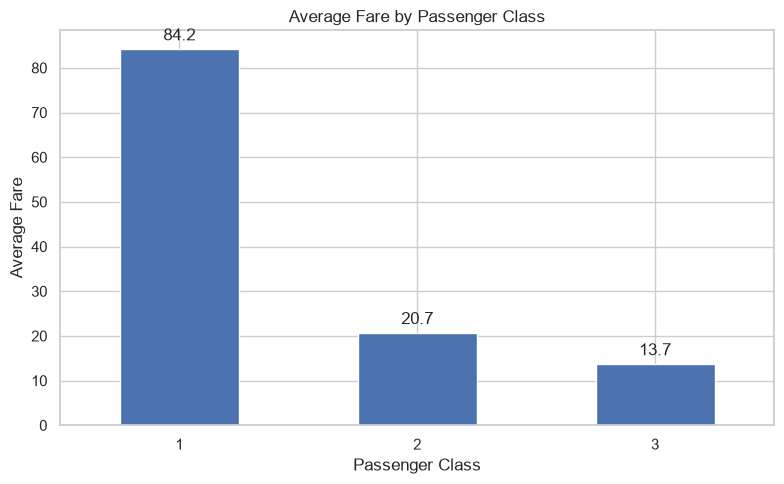

In [9]:
# Insight 3: Average fare by passenger class

avg_fare_by_class = df.groupby("pclass")["fare"].mean()

plt.figure(figsize=(8, 5))
ax = avg_fare_by_class.plot(kind="bar")

plt.title("Average Fare by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Average Fare")
plt.xticks(rotation=0)

for i, value in enumerate(avg_fare_by_class):
    ax.text(i, value + 2, f"{value:.1f}", ha="center")

plt.tight_layout()
plt.show()

In [10]:
# Insight 4: Survival rate by age group

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)

survival_by_age = df.groupby(
    "age_group",
    observed=False
)["survived"].mean() * 100

plt.figure(figsize=(9, 5))
ax = survival_by_age.plot(kind="bar")

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)

for i, value in enumerate(survival_by_age):
    if pd.notna(value):
        ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()""

SyntaxError: invalid syntax (321461430.py, line 27)

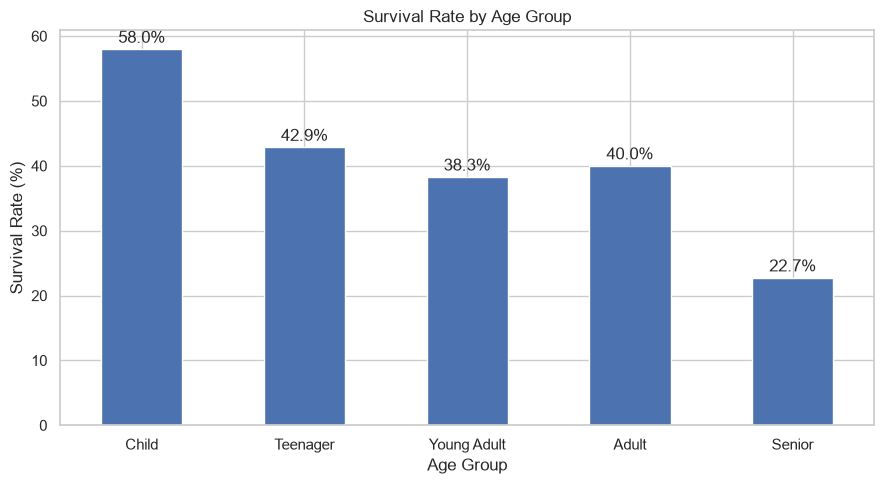

In [11]:
# Insight 4: Survival rate by age group

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)

survival_by_age = df.groupby(
    "age_group",
    observed=False
)["survived"].mean() * 100

plt.figure(figsize=(9, 5))
ax = survival_by_age.plot(kind="bar")

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)

for i, value in enumerate(survival_by_age):
    if pd.notna(value):
        ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

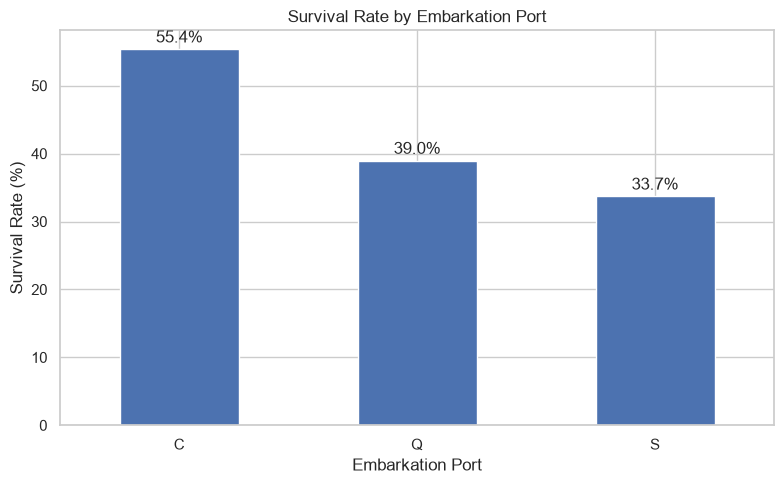

In [12]:
# Insight 5: Survival rate by embarkation port

survival_by_port = df.groupby("embarked")["survived"].mean() * 100

plt.figure(figsize=(8, 5))
ax = survival_by_port.plot(kind="bar")

plt.title("Survival Rate by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)

for i, value in enumerate(survival_by_port):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

# Business Insights from EDA

### Insight 1 — Passenger Class and Survival
Passenger class is associated with survival outcomes. Survival rates differ considerably across passenger classes, indicating that class was an important factor in the dataset.

### Insight 2 — Gender and Survival
Survival rates differ substantially between male and female passengers, showing a strong association between gender and survival outcomes.

### Insight 3 — Passenger Class and Fare
Average fare varies considerably across passenger classes. Higher passenger classes have higher average ticket fares.

### Insight 4 — Age Group and Survival
Survival rates vary across age groups. This indicates that age was another factor associated with survival outcomes.

### Insight 5 — Embarkation Port and Survival
Survival rates differ across embarkation ports, suggesting that the passenger groups entering through different ports had different survival outcomes.

# EDA Conclusion

The exploratory analysis identified relationships between passenger class, gender, age group, fare, embarkation port, and survival outcomes.

The analysis demonstrates a complete EDA workflow:

- Dataset profiling
- Data quality assessment
- Summary statistics
- Distribution analysis
- Correlation analysis
- Business-oriented visualisation
- Insight generation

These findings can be used as a starting point for deeper statistical analysis or predictive modelling.